In [1]:
# Cell 1: import required library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
import torch
from pathlib import Path
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import models, transforms
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, precision_recall_curve, brier_score_loss
from PIL import Image

In [2]:
# Cell 2: Load data & setups
# Paths
PROCESSED_DIR = Path("../data/processed")
LOGS = Path("../reports/experiments")
MODELS_DIR = Path("../models/classification")
FIGURES_DIR = Path("../reports/figures/analysis")
FIGURES_DIR.mkdir(parents=True, exist_ok= True)
RAW_DATA_DIR = Path("../data/raw/data1a")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load logs
exp_logs = pd.read_csv(LOGS / "experiment_log.csv")
print("Experiment Log Summary:")
print(exp_logs[["experiment_id", "model_name", "accuracy", "recall", "f1_score"]].round(4))

# Recreate test loader
val_test_transforms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class CarDamageDataset(torch.utils.data.Dataset):
    def __init__(self, dataframe, root_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        img_path = self.root_dir / self.df.loc[idx, "image_path"]
        label = self.df.loc[idx, "target"]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label

df_test = pd.read_csv(PROCESSED_DIR / "test_split.csv")
test_loader = DataLoader(CarDamageDataset(df_test, RAW_DATA_DIR, val_test_transforms), batch_size=32, shuffle=False)

Experiment Log Summary:
  experiment_id             model_name  accuracy  recall  f1_score
0        EXP-00  DecisionTree_Metadata    0.8555  1.0000    0.8731
1        EXP-01             Custom_CNN    0.7110  0.7616    0.7238
2        EXP-02        ResNet18_Frozen    0.9249  0.9186    0.9240
3        EXP-03     ResNet18_FineTuned    0.9595  0.9651    0.9595
4        EXP-04  MobileNetV3_FineTuned    0.9162  0.8663    0.9113
5        EXP-05        EfficientNet_B0    0.9335  0.9012    0.9309


In [3]:
# Cell 3: Load the Champion Model and Get Predictions
# ResNet18 was the best model

# 1. Load model architecture and weights
model = models.resnet18(weights=None)         # not need ImageNet weights now
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)
model.load_state_dict(torch.load(MODELS_DIR / "exp03_resnet18_finetuned.pth", weights_only=True))
model = model.to(device)
model.eval()


# Get Predictions
all_probs, all_labels, all_paths = [], [], []

with torch.no_grad():
    for i, (images, labels) in enumerate(test_loader):
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)[:, 1]  # probability of Damage

        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.numpy())

# Add to DataFrame for analysis
df_test["prob_damaged"] = all_probs
df_test["pred_05"] = (df_test["prob_damaged"] >= 0.5).astype(int)
print("Predictions generated for all test images.")


Predictions generated for all test images.


In [4]:
# Cell 4: Bootstrap Confidence Intervals 
from sklearn.utils import resample

def bootstrap_ci(y_true, y_pred, n_bootstraps = 1000, ci=95):
    scores = []
    n = len(y_true)
    for _ in range(n_bootstraps):
        indices = np.random.randint(0, n, n)
        if len(np.unique(y_true[indices])) < 2:
            continue
        scores.append((y_true[indices] == y_pred[indices]).mean())
    lower = np.percentile(scores, (100 - ci) / 2)
    upper = np.percentile(scores, 100 - (100 - ci) / 2)
    return np.mean(scores), lower, upper

y_true = df_test["target"].values
y_pred = df_test["pred_05"].values

mean_acc, lower_acc, upper_acc = bootstrap_ci(y_true, y_pred)
print(f"EXP-03 Test Accuracy: {mean_acc:.4f}")
print(f"95% Confidence Interval: [{lower_acc:.4f}, {upper_acc:.4f}]")
print(f"Error Margin: ±{(upper_acc - lower_acc)/2 * 100:.2f}%")

EXP-03 Test Accuracy: 0.9597
95% Confidence Interval: [0.9364, 0.9798]
Error Margin: ±2.17%


In [5]:
# Cell 5 (Fixed): Shortcut-Conflict Test
from sklearn.tree import DecisionTreeClassifier

# 1. Add the predictions back to df_test (they were lost when we reloaded)
# We need to re-run the model evaluation quickly to get these back
model.eval()
all_probs, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.numpy())

df_test["prob_damaged"] = all_probs
df_test["pred_05"] = (df_test["prob_damaged"] >= 0.5).astype(int)

# 2. Train metadata baseline
df_train = pd.read_csv(PROCESSED_DIR / "train_split.csv")
features = ["width", "height", "aspect_ratio"]
dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt.fit(df_train[features], df_train["target"])

# 3. Get baseline predictions on test set
df_test["baseline_pred"] = dt.predict(df_test[features])

# 4. Find the "conflict" images (where baseline is wrong)
conflict_df = df_test[df_test["baseline_pred"] != df_test["target"]]
print(f"Total test images: {len(df_test)}")
print(f"Conflict images (baseline failed): {len(conflict_df)}")

# 5. Evaluate ResNet18 on these conflict images
if len(conflict_df) > 0:
    resnet_acc_on_conflict = (conflict_df["pred_05"] == conflict_df["target"]).mean()
    print(f"Metadata Baseline Accuracy on Conflict Images: 0.0%")
    print(f"ResNet18 (EXP-03) Accuracy on Conflict Images: {resnet_acc_on_conflict*100:.2f}%")
    
    if resnet_acc_on_conflict > 0.5:
        print("\nSUCCESS: ResNet18 correctly classifies the images the size-rule gets wrong.")
        print("This strongly suggests ResNet18 is learning actual visual damage, not just image size.")
    else:
        print("\nResNet18 also fails on these images. It might be relying on size.")

Total test images: 346
Conflict images (baseline failed): 50
Metadata Baseline Accuracy on Conflict Images: 0.0%
ResNet18 (EXP-03) Accuracy on Conflict Images: 86.00%

SUCCESS: ResNet18 correctly classifies the images the size-rule gets wrong.
This strongly suggests ResNet18 is learning actual visual damage, not just image size.


In [6]:
# ell 6: Threshold Analysis
thresholds = [0.30, 0.40, 0.50, 0.60]
results = []

y_true = df_test["target"].values

for thresh in thresholds:
    preds = (df_test["prob_damaged"] >= thresh).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()

    acc = (tp + tn) / (tp + tn + fp + fn)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0
    
    results.append({
        "Threshold": thresh,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1,
        "False Negatives": fn,
        "False Positives": fp
    })

df_thresh = pd.DataFrame(results)
print("--- Threshold Comparison ---")
print(df_thresh.round(4).to_string(index=False))

# Recommendation
best_thresh = df_thresh.iloc[df_thresh["Recall"].argmax()]
print(f"\nFor insurance, maximizing Recall is key. The threshold {best_thresh['Threshold']} catches the most damage (Recall: {best_thresh['Recall']:.4f}), but creates {best_thresh['False Positives']} false alarms.")

--- Threshold Comparison ---
 Threshold  Accuracy  Precision  Recall     F1  False Negatives  False Positives
       0.3    0.9566     0.9435  0.9709 0.9570                5               10
       0.4    0.9595     0.9489  0.9709 0.9598                5                9
       0.5    0.9595     0.9540  0.9651 0.9595                6                8
       0.6    0.9595     0.9540  0.9651 0.9595                6                8

For insurance, maximizing Recall is key. The threshold 0.3 catches the most damage (Recall: 0.9709), but creates 10.0 false alarms.


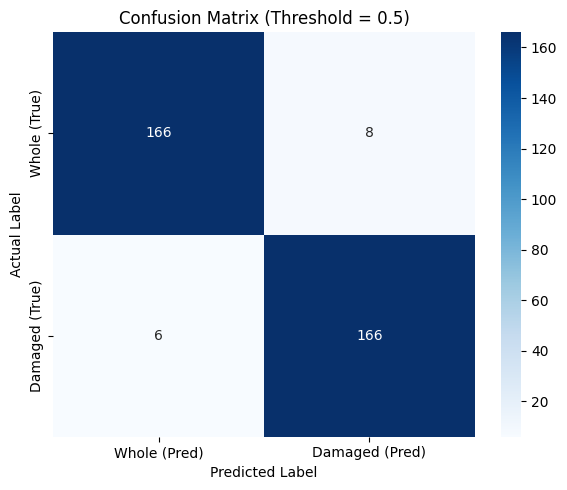

False Negatives (Missed Damage): 6
False Positives (False Alarms): 8


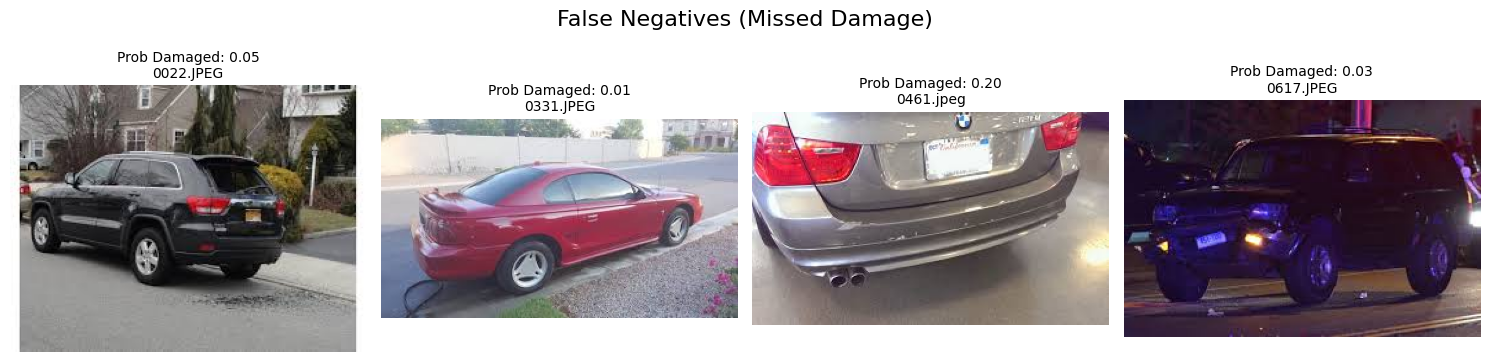

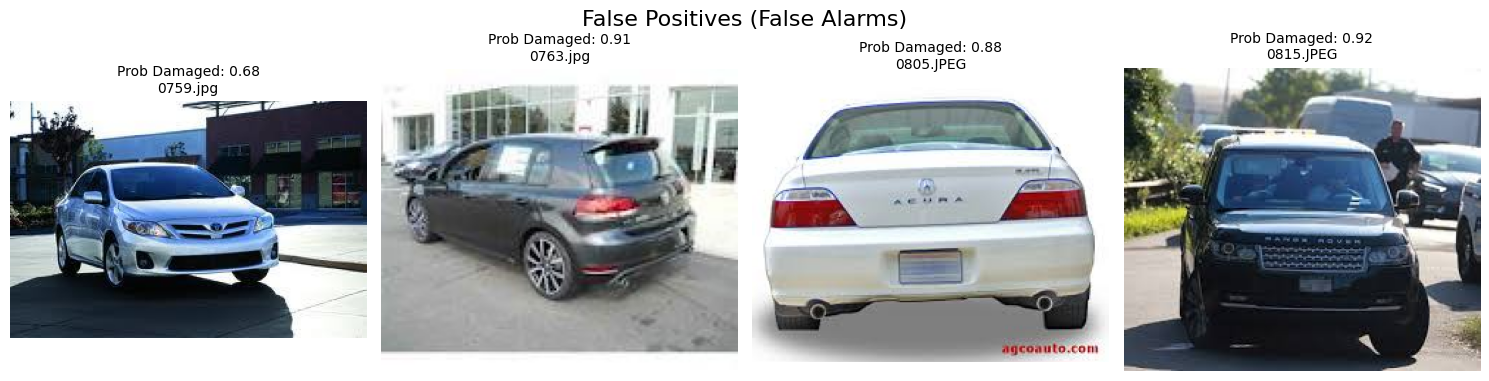

In [7]:
# Cell 7: Error Analysis
# 1. Confusion Matrix
cm = confusion_matrix(y_true, df_test["pred_05"])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',xticklabels=['Whole (Pred)', 'Damaged (Pred)'],
            yticklabels=['Whole (True)', 'Damaged (True)'])

plt.title("Confusion Matrix (Threshold = 0.5)")
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrix.png", dpi=150)
plt.show()

# 2. Visualize False Negatives and False Positives
fn_df = df_test[(df_test["target"] == 1) & (df_test["pred_05"] == 0)]
fp_df = df_test[(df_test["target"] == 0) & (df_test["pred_05"] == 1)]

print(f"False Negatives (Missed Damage): {len(fn_df)}")
print(f"False Positives (False Alarms): {len(fp_df)}")

def plot_errors(df_errors, title, num_images=4):
    if len(df_errors) == 0: return
    fig, axes = plt.subplots(1, min(num_images, len(df_errors)), figsize=(15, 4))
    fig.suptitle(title, fontsize=16)
    if min(num_images, len(df_errors)) == 1: axes = [axes]
    
    for ax, (_, row) in zip(axes, df_errors.head(num_images).iterrows()):
        img = Image.open(RAW_DATA_DIR / row["image_path"])
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"Prob Damaged: {row['prob_damaged']:.2f}\n{row['filename']}", fontsize=10)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{title.replace(' ', '_')}.png", dpi=150)
    plt.show()

plot_errors(fn_df, "False Negatives (Missed Damage)")
plot_errors(fp_df, "False Positives (False Alarms)")

In [8]:
# Cell 8: Validation Predictions & Threshold Selection
# 1. Load validation set
df_val = pd.read_csv(PROCESSED_DIR / "val_split.csv")
val_loader = DataLoader(CarDamageDataset(df_val, RAW_DATA_DIR, val_test_transforms), batch_size=32, shuffle=False)

# 2. Get validation predictions
val_probs, val_labels = [], []
model.eval()
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        val_probs.extend(probs.cpu().numpy())
        val_labels.extend(labels.numpy())

val_probs = np.array(val_probs)
val_labels = np.array(val_labels)

# 3. Find threshold on VALIDATION to achieve >= 0.97 recall
target_recall = 0.97
rows = []
for t in np.arange(0.05, 0.96, 0.05):
    pred = (val_probs >= t).astype(int)
    tp = ((pred == 1) & (val_labels == 1)).sum()
    fn = ((pred == 0) & (val_labels == 1)).sum()
    fp = ((pred == 1) & (val_labels == 0)).sum()
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rows.append((round(t, 2), rec, prec, fn, fp))

th_df = pd.DataFrame(rows, columns=["thr", "recall", "precision", "FN", "FP"])
# Find the highest threshold that still meets the recall target
valid_thresholds = th_df[th_df["recall"] >= target_recall]
chosen_threshold = valid_thresholds["thr"].max()

print("--- Validation Threshold Analysis ---")
print(th_df.to_string(index=False))
print(f"\nChosen Threshold (from Validation): {chosen_threshold}")

# 4. Apply this threshold ONCE to the Test set
y_test = df_test["target"].values
test_probs = df_test["prob_damaged"].values
test_preds_final = (test_probs >= chosen_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, test_preds_final).ravel()
test_rec = tp / (tp + fn)
test_prec = tp / (tp + fp)

print(f"\n--- Final Test Evaluation at Threshold {chosen_threshold} ---")
print(f"Test Recall: {test_rec:.4f} (FN: {fn})")
print(f"Test Precision: {test_prec:.4f} (FP: {fp})")

--- Validation Threshold Analysis ---
 thr   recall  precision  FN  FP
0.05 0.982456   0.831683   3  34
0.10 0.982456   0.848485   3  30
0.15 0.976608   0.883598   4  22
0.20 0.976608   0.888298   4  21
0.25 0.970760   0.892473   5  20
0.30 0.964912   0.901639   6  18
0.35 0.947368   0.900000   9  18
0.40 0.947368   0.900000   9  18
0.45 0.947368   0.905028   9  17
0.50 0.941520   0.904494  10  17
0.55 0.929825   0.903409  12  17
0.60 0.923977   0.908046  13  16
0.65 0.918129   0.912791  14  15
0.70 0.912281   0.917647  15  14
0.75 0.894737   0.932927  18  11
0.80 0.883041   0.937888  20  10
0.85 0.877193   0.961538  21   6
0.90 0.859649   0.967105  24   5
0.95 0.836257   0.966216  28   5

Chosen Threshold (from Validation): 0.25

--- Final Test Evaluation at Threshold 0.25 ---
Test Recall: 0.9709 (FN: 5)
Test Precision: 0.9330 (FP: 12)


In [9]:
# Cell 9: McNemar Test & Conflict Breakdown
from scipy.stats import binomtest

# 1. Load EXP-05 (EfficientNet) for comparison
# We need its predictions to compare with EXP-03
model_exp05 = models.efficientnet_b0(weights=None)
model_exp05.classifier[1] = nn.Linear(model_exp05.classifier[1].in_features, 2)
model_exp05.load_state_dict(torch.load(MODELS_DIR / "exp05_efficientnet_b0.pth", weights_only=True))
model_exp05 = model_exp05.to(device).eval()

preds_05 = []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_exp05(images)
        _, predicted = torch.max(outputs, 1)
        preds_05.extend(predicted.cpu().numpy())

preds_03 = df_test["pred_05"].values
y_test = df_test["target"].values

# McNemar Test
c3 = (preds_03 == y_test)
c5 = (np.array(preds_05) == y_test)
b = (c3 & ~c5).sum()
c = (~c3 & c5).sum()
p_value = binomtest(b, b + c, 0.5).pvalue
print(f"McNemar Test (EXP-03 vs EXP-05): only-03-right={b}, only-05-right={c}, p-value={p_value:.4f}")
if p_value > 0.05:
    print("-> The difference is NOT statistically significant.")

# 2. Conflict Breakdown
conflict_df = df_test[df_test["baseline_pred"] != df_test["target"]]
fp_df = df_test[(df_test["target"] == 0) & (df_test["pred_05"] == 1)]
fp_in_conflict = fp_df[fp_df.index.isin(conflict_df.index)]

print(f"\nTotal False Positives: {len(fp_df)}")
print(f"False Positives inside Conflict Set (small whole cars): {len(fp_in_conflict)}")
print(f"Error rate on small whole images: {len(fp_in_conflict)/50*100:.1f}%")
print(f"Error rate on larger whole images: {(len(fp_df)-len(fp_in_conflict))/124*100:.1f}%")

McNemar Test (EXP-03 vs EXP-05): only-03-right=18, only-05-right=9, p-value=0.1221
-> The difference is NOT statistically significant.

Total False Positives: 8
False Positives inside Conflict Set (small whole cars): 7
Error rate on small whole images: 14.0%
Error rate on larger whole images: 0.8%


In [10]:
# Cell 10: Speed Benchmark
import time
def bench(model, n=100):
    model.eval()
    x = torch.randn(1, 3, 224, 224).to(device)
    with torch.no_grad():
        for _ in range(10): model(x)
        if device.type == 'cuda': torch.cuda.synchronize()
        t = time.time()
        for _ in range(n): model(x)
        if device.type == 'cuda': torch.cuda.synchronize()
    return (time.time() - t) / n * 1000

print("Benchmarking (ms/image)...")
print(f"EXP-03 (ResNet18): {bench(model):.2f} ms")
print(f"EXP-05 (EfficientNet): {bench(model_exp05):.2f} ms")

Benchmarking (ms/image)...
EXP-03 (ResNet18): 3.74 ms
EXP-05 (EfficientNet): 11.78 ms


In [11]:
# Cell 11: Real Benchmarks and Parameter Counts
import time

# 1. Load all three models with 2-class heads
model_03 = models.resnet18(weights=None)
model_03.fc = nn.Linear(model_03.fc.in_features, 2)
model_03.load_state_dict(torch.load(MODELS_DIR / "exp03_resnet18_finetuned.pth", weights_only=True))
model_03 = model_03.to(device).eval()

model_04 = models.mobilenet_v3_small(weights=None)
model_04.classifier[3] = nn.Linear(model_04.classifier[3].in_features, 2)
model_04.load_state_dict(torch.load(MODELS_DIR / "exp04_mobilenetv3.pth", weights_only=True))
model_04 = model_04.to(device).eval()

model_05 = models.efficientnet_b0(weights=None)
model_05.classifier[1] = nn.Linear(model_05.classifier[1].in_features, 2)
model_05.load_state_dict(torch.load(MODELS_DIR / "exp05_efficientnet_b0.pth", weights_only=True))
model_05 = model_05.to(device).eval()

# 2. Print real counts
print("--- Actual Parameter Counts & Sizes ---")
for name, m in {"EXP-03 ResNet18": model_03, "EXP-04 MobileNetV3": model_04, "EXP-05 EfficientNet": model_05}.items():
    n = sum(p.numel() for p in m.parameters())
    print(f"{name}: {n/1e6:.2f}M params, {n*4/1e6:.1f} MB")

# 3. Benchmark all three models correctly
def bench(model, n=200):
    model.eval()
    x = torch.randn(1, 3, 224, 224).to(device)
    with torch.no_grad():
        for _ in range(20): model(x)  # Warm-up
        if device.type == 'cuda': torch.cuda.synchronize()
        t = time.time()
        for _ in range(n): model(x)
        if device.type == 'cuda': torch.cuda.synchronize()
    return (time.time() - t) / n * 1000

print("\n--- Inference Speed (ms/image) ---")
print(f"EXP-03 ResNet18: {bench(model_03):.2f} ms")
print(f"EXP-04 MobileNetV3: {bench(model_04):.2f} ms")
print(f"EXP-05 EfficientNet: {bench(model_05):.2f} ms")

--- Actual Parameter Counts & Sizes ---
EXP-03 ResNet18: 11.18M params, 44.7 MB
EXP-04 MobileNetV3: 1.52M params, 6.1 MB
EXP-05 EfficientNet: 4.01M params, 16.0 MB

--- Inference Speed (ms/image) ---
EXP-03 ResNet18: 3.64 ms
EXP-04 MobileNetV3: 8.14 ms
EXP-05 EfficientNet: 12.69 ms


In [12]:
# Cell 12: Calibration (Expected Calibration Error)
def ece(p, y, bins=10):
    edges, e = np.linspace(0, 1, bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & ((p < hi) if hi < 1 else (p <= hi))
        if m.any(): e += m.mean() * abs(y[m].mean() - p[m].mean())
    return e

# We have val_probs and val_labels from earlier (Cell 8)
print(f"ECE (Validation): {ece(val_probs, val_labels):.4f}")
print(f"ECE (Test): {ece(df_test['prob_damaged'].values, df_test['target'].values):.4f}")

ECE (Validation): 0.0469
ECE (Test): 0.0260


In [13]:
# Cell 13: Conflict-Set at Threshold 0.25
y_test = df_test["target"].values
probs_test = df_test["prob_damaged"].values

# At 0.25
pred_025 = (probs_test >= 0.25).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_025).ravel()

# Recreate baseline predictions
from sklearn.tree import DecisionTreeClassifier
df_train = pd.read_csv(PROCESSED_DIR / "train_split.csv")
dt = DecisionTreeClassifier(max_depth=3, random_state=42).fit(df_train[["width", "height", "aspect_ratio"]], df_train["target"])
df_test["baseline_pred"] = dt.predict(df_test[["width", "height", "aspect_ratio"]])

conflict_mask = df_test["baseline_pred"] != df_test["target"]
fp_mask_025 = (pred_025 == 1) & (y_test == 0)
fp_in_conflict_025 = (fp_mask_025 & conflict_mask).sum()

print(f"At Threshold 0.25:")
print(f"Total False Positives: {fp}")
print(f"False Positives in Conflict Set: {fp_in_conflict_025}")
print(f"Error rate on small whole images (n=50): {fp_in_conflict_025/50*100:.1f}%")
print(f"Error rate on larger whole images (n=124): {(fp - fp_in_conflict_025)/124*100:.1f}%")

# Low-confidence count
low_conf = ((probs_test >= 0.3) & (probs_test <= 0.7)).sum()
low_conf_errors = ((probs_test >= 0.3) & (probs_test <= 0.7) & (pred_025 != y_test)).sum()
print(f"\nLow-confidence (0.3-0.7) images: {low_conf} | Errors among them: {low_conf_errors}")

At Threshold 0.25:
Total False Positives: 12
False Positives in Conflict Set: 11
Error rate on small whole images (n=50): 22.0%
Error rate on larger whole images (n=124): 0.8%

Low-confidence (0.3-0.7) images: 7 | Errors among them: 3


In [14]:
# Cell 14: Save Metrics
METRICS_DIR = Path("../reports/metrics")
METRICS_DIR.mkdir(parents=True, exist_ok=True)

pd.DataFrame({"y_true": val_labels, "prob": val_probs}).to_csv(METRICS_DIR / "val_predictions.csv", index=False)
pd.DataFrame({"y_true": y_test, "prob": probs_test}).to_csv(METRICS_DIR / "test_predictions.csv", index=False)
print("Saved val and test predictions to reports/metrics/")

Saved val and test predictions to reports/metrics/


In [15]:
# Cell 15: Validation Conflict Check

# 1. Train the size rule (Decision Tree) on the TRAINING set
df_train = pd.read_csv(PROCESSED_DIR / "train_split.csv")
dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt.fit(df_train[["width", "height", "aspect_ratio"]], df_train["target"])

# 2. Apply the size rule to the VALIDATION set to find conflict images
df_val = pd.read_csv(PROCESSED_DIR / "val_split.csv")
val_baseline_preds = dt.predict(df_val[["width", "height", "aspect_ratio"]])

# "conflict-style small images" = validation images that are ACTUALLY whole,
# but the metadata rule calls them damaged (baseline_pred=1, true_label=0)
small_val = (val_baseline_preds == 1) & (df_val["target"] == 0)

# 3. Get model predictions at threshold 0.25 on validation
pred25_v = (val_probs >= 0.25).astype(int)
y_val = df_val["target"].values

# 4. Count false positives at 0.25
fp_v = (pred25_v == 1) & (y_val == 0)
fp_in_conflict = (fp_v & small_val).sum()

print(f"--- Validation Conflict Analysis (Threshold 0.25) ---")
print(f"Total validation images: {len(df_val)}")
print(f"Total validation false positives: {fp_v.sum()}")
print(f"False positives in conflict set (small whole images): {fp_in_conflict}")
print(f"Total conflict-style small images in validation: {small_val.sum()}")

if small_val.sum() > 0:
    print(f"Error rate on small whole images (val): {fp_in_conflict / small_val.sum() * 100:.1f}%")
    
non_small_val = (~small_val) & (y_val == 0)
if non_small_val.sum() > 0:
    fp_non_small = (fp_v & non_small_val).sum()
    print(f"Error rate on larger whole images (val): {fp_non_small / non_small_val.sum() * 100:.1f}%")

--- Validation Conflict Analysis (Threshold 0.25) ---
Total validation images: 343
Total validation false positives: 20
False positives in conflict set (small whole images): 16
Total conflict-style small images in validation: 53
Error rate on small whole images (val): 30.2%
Error rate on larger whole images (val): 3.4%


## Notebook 05 Summary: Model Comparison and Error Analysis

**Model selection:** EXP-03 (ResNet18, layer4 fine-tuned) is the primary model: lowest validation loss (0.2204), highest validation accuracy at its best-loss checkpoint (0.921 vs ~0.88 for EXP-02/04/05), and highest test F1 among the neural models. Selection was made on validation metrics, not test. EfficientNet-B0 (EXP-05) is the runner-up. McNemar test on test at threshold 0.5: EXP-03 correct where EXP-05 was wrong on 18 images, the reverse on 9 (p = 0.1221), so the two are not statistically distinguishable at n = 346. EXP-03 is also ~3.5x faster (3.64 vs 12.69 ms/image), which supports choosing it for deployment.

**Test performance, EXP-03 (n = 346, positive class = damaged)**

| Threshold | TN | FP | FN | TP | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|---|---|---|
| 0.50 | 166 | 8 | 6 | 166 | 0.9595 | 0.9540 | 0.9651 | 0.9595 |
| 0.25 (chosen) | 162 | 12 | 5 | 167 | 0.9509 | 0.9330 | 0.9709 | 0.9516 |

- ROC-AUC 0.9929, PR-AUC 0.98. 95% bootstrap CIs at 0.5: accuracy [0.936, 0.980], recall [0.93, 0.99].
- Validation vs test accuracy (threshold 0.5): 0.9213 vs 0.9595. Test is higher for every model (Notebook 04), so test numbers are likely optimistic and validation is the primary estimate.
- Calibration: ECE 0.047 (val), 0.026 (test), so probabilities are fairly well calibrated (10 bins, small n, noisy estimate).

**Threshold analysis (chosen on validation, applied once to test)**
- Rule: highest threshold with validation damaged-recall >= 0.97. Chosen 0.25 (val recall 0.9708, precision 0.8925, FN 5, FP 20). Saved in `params.yaml`.
- On test, 0.25 vs 0.5: one fewer missed damaged car (5 vs 6) for four more false alarms (12 vs 8). Validation recall falls smoothly from 0.98 (thr 0.05) to 0.84 (thr 0.95), so 0.25 is a reasonable, not uniquely optimal, choice.

**Shortcut-conflict analysis** (small whole images that the metadata-only baseline misclassifies as damaged; 50 in test, 53 in validation)
- At threshold 0.5 (test): EXP-03 gets 86% right (43/50, 95% CI ~[0.74, 0.93]); 7 of its 8 false positives are in this group (14% error vs ~0.8% on the other 124 whole images).
- At the operating threshold 0.25:

| Set | False positives | In small-whole group | Small-image error | Larger-image error |
|---|---|---|---|---|
| Test | 12 | 11 | 22.0% (11/50) | 0.8% (1/124) |
| Validation | 20 | 16 | 30.2% (16/53) | 3.4% (4/119) |
| Combined | 32 | 27 | 26.2% (27/103) | 2.1% (5/243) |

- Interpretation: the model is not using image size alone (test accuracy on these images is far above the baseline's 0%), but it retains clear size sensitivity: 84% of false alarms (27/32) are small whole images, and the pattern replicates on independent validation data, so it is a real model behavior, not a test-set artifact. Lowering the threshold from 0.5 to 0.25 amplifies it (test: 7 to 11 false positives in this group).
- The test set has no large damaged images, so the reverse case cannot be tested here. **OOD evaluation: pending.**

**Error analysis (threshold 0.5 unless stated)**

| Group | Count | Observations |
|---|---|---|
| False negatives | 6 (5 at 0.25) | Visual inspection (subjective): no visible damage from the pictured angle / possible label noise (4), minor damage (1), low light (1). Inspected examples had probabilities 0.01-0.20. |
| False positives | 8 (12 at 0.25) | At 0.5: 7 small whole images, 1 larger whole image. At 0.25: 11 of 12 small whole images. |
| Low-confidence (0.3-0.7), test | 7 | 3 of 7 are errors (57% correct vs ~95% overall); suggests routing this band to human review. |

- Example: a night-time image with front-end damage was missed at probability 0.03 (low-light failure).

**Efficiency** (RTX 3050, batch 1, forward pass only, fp32, after warm-up, median of ___ runs)

| Model | Params (2-class head) | Size (MB) | ms/image | Test F1 (0.5) |
|---|---|---|---|---|
| EXP-03 ResNet18 | 11.18M | 44.7 | 3.64 | 0.9595 |
| EXP-04 MobileNetV3-Small | 1.52M | 6.1 | 8.14 | 0.9113 |
| EXP-05 EfficientNet-B0 | 4.01M | 16.0 | 12.69 | 0.9309 |

- MobileNetV3-Small is the smallest but slower than ResNet18 on this GPU at batch 1 (many small depthwise layers, launch-bound); its advantage would appear on CPU/mobile, which was not measured. Run-to-run variation is ~7% (an earlier run gave 3.41 and 12.21 ms for ResNet18 and EfficientNet-B0).

**Limitations**
- Known source/resolution shortcut in the dataset; metadata baseline reaches 0.8555 test accuracy.
- The planned downscale+JPEG degradation augmentation (EDA action) was not implemented; the replicated size sensitivity above is consistent with this gap.
- Small test set (n = 346): differences of 2-3 points are not significant.
- The test set was evaluated after every experiment; the model and threshold were chosen on validation.
- Error-cause labels come from visual inspection of a few images and are subjective.
- OOD generalization not yet verified.

**Artifacts:** validation and test probabilities in `reports/metrics/`, chosen threshold in `params.yaml`, experiment log in `reports/experiments/experiment_log.csv`, checkpoints in `models/classification/` (DVC).

**Next:** Notebook 06, Grad-CAM on correct predictions (control), false negatives, and the small-image false positives. Optional follow-up (EXP-06): retrain ResNet18 with downscale+JPEG degradation on both classes and compare the small-image false-positive rate (22% test / 30% val at 0.25).